<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture guide](README.md)

# 01 · A filled preview summary can hide metadata problems

Which stored pages meet a small preview-publication policy? A title might come from Open Graph, Twitter Card metadata or the HTML title element. A tidy summary can also conceal conflicting titles or prefer a small first image over a larger later image. We will retain the raw tag order alongside the summary and apply an explicit, adjustable policy.

**Deterministic synthetic HTML fixtures:** nine deliberately constructed page records, including one missing HTML input. They are examples, not a sampled website. The real TypeScript parser runs through VGI. No pages or images are fetched, no crawler is started, and URLs under `example.test` are illustrative identifiers.

## Choose whether the title must be explicit Open Graph

`REQUIRE_OG_TITLE` is a Boolean. Default **False** allows the worker's title fallbacks. **True** additionally requires a retained nonblank `og:title` tag.

Both policies require a parsed title, description, image URL and page URL, and reject **conflicting distinct `og:title` values**. Missing HTML is unavailable, not a failed content audit. This is a small example policy, not full Open Graph validation or a guarantee of rendering in any platform. Restart Kernel → Run All after editing.

In [1]:
REQUIRE_OG_TITLE = False  # Experiment: True; parsed metadata stays unchanged

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap

assert isinstance(REQUIRE_OG_TITLE, bool)
fixture_hash = hashlib.sha256(Path("fixtures/pages.json").read_bytes()).hexdigest()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)
colors = {"Accepted": "#287d85", "Needs review": "#bd7735", "Unavailable HTML": "#888888"}


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Synthetic HTML fixtures · real vgi-opengraph parser · local parse only · no page or image requests",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.91))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-opengraph/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-opengraph/notebooks/pyproject.toml.

## Parse once, preserving raw and resolved views

The literal Bun launch fetches an immutable remote Git revision and uses its frozen lockfile, with a versioned cache. It needs no local worker checkout. We read the synthetic JSON corpus into one ordinary table, then materialize summaries and ordered tags.

The two-argument parser resolves relative URLs using each page URL and any HTML `<base href>`. The one-argument view shows what was available without that supplied page URL; an absolute HTML base can still resolve it. Resolution creates a URL string, not evidence that a resource exists or is an image.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'opengraph' (
 TYPE vgi,
 LOCATION 'bun run github_worker.ts Query-farm/vgi-opengraph 1f43dbfd70c2987613ccef729cc57affea112650 src/worker.ts'
);
CREATE TABLE pages AS SELECT * FROM read_json_auto('fixtures/pages.json');
CREATE TABLE parsed AS
SELECT *,opengraph.main.parse_opengraph(html,page_url) AS og,
 opengraph.main.parse_opengraph(html) AS without_page_url,
 opengraph.main.opengraph_tags(html) AS tags FROM pages;
CREATE TABLE tag_rows AS
SELECT page_id,t.ordinality AS tag_position,t.tag.property AS property,t.tag.content AS content
FROM parsed CROSS JOIN UNNEST(tags) WITH ORDINALITY AS t(tag,ordinality);
CREATE TABLE title_evidence AS
SELECT page_id,
 first(content ORDER BY tag_position) FILTER(WHERE property='og:title') AS first_og_title,
 first(content ORDER BY tag_position) FILTER(WHERE property='twitter:title') AS first_twitter_title,
 count(*) FILTER(WHERE property='og:title') AS og_title_tags,
 count(DISTINCT content) FILTER(WHERE property='og:title') AS distinct_og_titles
FROM tag_rows GROUP BY page_id;

,Count


In [4]:
%%sql parsed_table <<
SELECT p.page_id,p.label,p.html IS NOT NULL AS html_available,p.og.title AS chosen_title,
 CASE WHEN p.html IS NULL THEN 'Unavailable HTML'
 WHEN e.first_og_title IS NOT NULL THEN 'Open Graph'
 WHEN e.first_twitter_title IS NOT NULL THEN 'Twitter Card'
 WHEN p.og.title IS NOT NULL THEN 'HTML title' ELSE 'No title' END AS title_source,
 p.og.description AS chosen_description,p.og.image AS resolved_image,p.og.url AS page_identity_url
FROM parsed p LEFT JOIN title_evidence e USING(page_id) ORDER BY page_id;

,page_id,label,html_available,chosen_title,title_source,chosen_description,resolved_image,page_identity_url
0,A,Complete OG,True,Gardens & Rain,Open Graph,A complete example,https://example.test/cards/a.png,https://example.test/articles/a
1,B,Twitter fallback,True,Twitter B,Twitter Card,Twitter description,https://example.test/cards/b.png,https://example.test/articles/b
2,C,HTML title fallback,True,HTML C,HTML title,HTML description,https://example.test/cards/c.png,https://example.test/articles/c
3,D,Conflicting OG titles,True,First D,Open Graph,Both titles survive in raw tags,https://example.test/cards/d.png,https://example.test/articles/d
4,E,Ordered images,True,Two images E,Open Graph,First image is intentionally smaller,https://example.test/cards/small.png,https://example.test/articles/e
5,F,HTML base URL,True,Base F,Open Graph,Base controls relative URLs,https://cdn.example.test/assets/hero.png,https://example.test/articles/f
6,G,Missing image,True,No image G,Open Graph,A title does not imply an image,None,https://example.test/articles/g
7,H,Missing HTML,False,None,Unavailable HTML,None,None,None
8,I,Empty metadata,True,None,No title,None,None,None


The corpus has **9 records**, of which **8** have HTML. Chosen title sources: **5 Open Graph**, **1 Twitter Card**, **1 HTML title**, **1 missing**, and **1 unavailable inputs**. Fallbacks improve field coverage but do not add the missing explicit tags. Parsed fingerprint: `d89035033e1e3fae873e6786c4b3a66bc4c4302799cd667ea341fefb31029f92`.

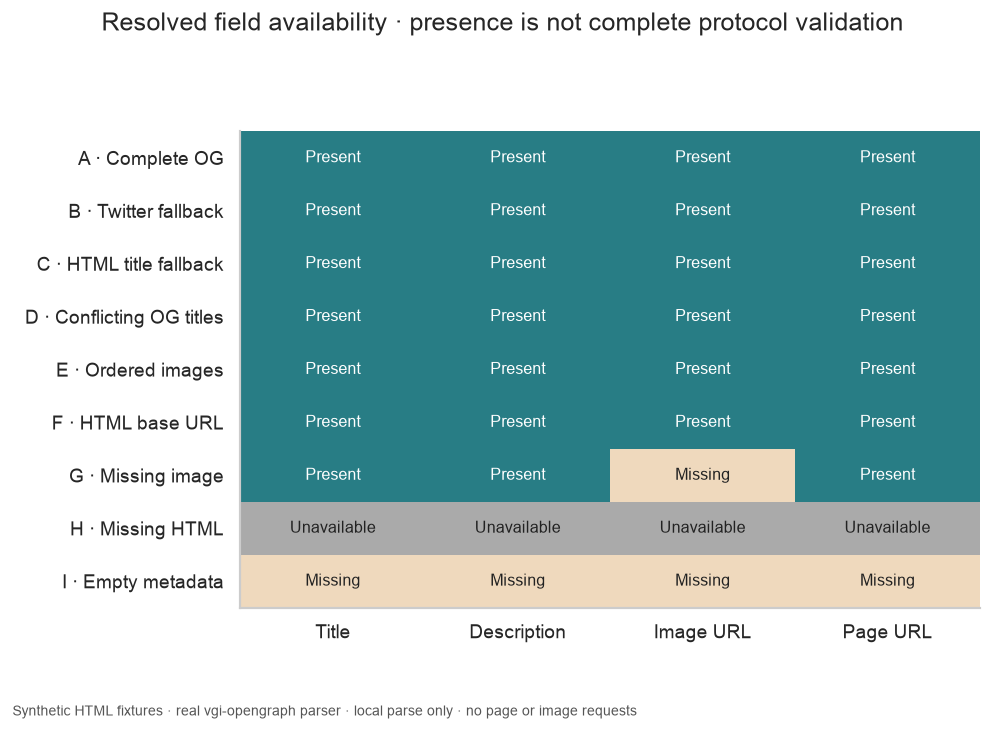

In [5]:
display(parsed_table)
assert con.execute("SELECT count(*)=count(DISTINCT page_id) AND count(*)>0 FROM pages").fetchone()[0]
assert len(parsed_table) == con.execute("SELECT count(*) FROM pages").fetchone()[0]
assert (
    con.execute("SELECT count(*) FROM parsed WHERE (html IS NULL) IS DISTINCT FROM (og IS NULL)").fetchone()[
        0
    ]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM parsed p JOIN title_evidence e USING(page_id) WHERE e.first_og_title IS NOT NULL AND p.og.title IS DISTINCT FROM e.first_og_title"
    ).fetchone()[0]
    == 0
)
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute("SELECT page_id,og,tags FROM parsed ORDER BY page_id").fetchall(),
        sort_keys=True,
        separators=(",", ":"),
    ).encode()
).hexdigest()
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "fixture_sha256": fixture_hash,
            "parsed_fingerprint": fingerprint,
            "require_og_title": REQUIRE_OG_TITLE,
        },
        indent=2,
    )
)
counts = parsed_table.title_source.value_counts()
prose(
    f"The corpus has **{len(parsed_table)} records**, of which **{int(parsed_table.html_available.sum())}** have HTML. Chosen title sources: **{counts.get('Open Graph', 0)} Open Graph**, **{counts.get('Twitter Card', 0)} Twitter Card**, **{counts.get('HTML title', 0)} HTML title**, **{counts.get('No title', 0)} missing**, and **{counts.get('Unavailable HTML', 0)} unavailable inputs**. Fallbacks improve field coverage but do not add the missing explicit tags. Parsed fingerprint: `{fingerprint}`."
)
fields = con.execute(
    "SELECT page_id,label,html IS NOT NULL AS available,og.title IS NOT NULL AS title,og.description IS NOT NULL AS description,og.image IS NOT NULL AS image,og.url IS NOT NULL AS page_url FROM parsed ORDER BY page_id"
).df()
matrix = np.array(
    [
        [int(getattr(r, f)) if r.available else 2 for f in ["title", "description", "image", "page_url"]]
        for r in fields.itertuples()
    ]
)
fig, ax = plt.subplots(figsize=(8, 5.8))
ax.grid(False)
ax.imshow(matrix, cmap=ListedColormap(["#efd9bd", "#287d85", "#aaaaaa"]), vmin=0, vmax=2, aspect="auto")
for i in range(len(fields)):
    for j in range(4):
        ax.text(
            j,
            i,
            ["Missing", "Present", "Unavailable"][matrix[i, j]],
            ha="center",
            va="center",
            fontsize=9,
            color="white" if matrix[i, j] == 1 else "#222222",
        )
ax.set(
    xticks=range(4),
    xticklabels=["Title", "Description", "Image URL", "Page URL"],
    yticks=range(len(fields)),
    yticklabels=[f"{r.page_id} · {r.label}" for r in fields.itertuples()],
)
fig.suptitle("Resolved field availability · presence is not complete protocol validation")
finish(fig)

## Inspect evidence that the summary compresses away

The worker retains the first nonblank occurrence of a property after entity decoding and whitespace normalization. Later distinct `og:title` values remain in the raw tags, although the summary shows only the first. Here we deliberately flag conflicting titles; repeated identical titles would not satisfy that conflict test.

Repeated images are different: the [Open Graph protocol](https://ogp.me/) supports ordered image arrays, with structured properties following their image root. Our example keeps the first image and its dimensions together. The policy does not reject multiple images or choose the largest one. The parser's `images` list contains Open Graph images; a Twitter image fallback can fill `image` while leaving that list empty.

In [6]:
%%sql conflicts <<
SELECT t.page_id,t.tag_position,t.content AS raw_og_title,p.og.title AS chosen_title
FROM tag_rows t JOIN title_evidence e USING(page_id) JOIN parsed p USING(page_id)
WHERE t.property='og:title' AND e.distinct_og_titles>1 ORDER BY page_id,tag_position;

In [7]:
%%sql images_table <<
SELECT page_id,label,without_page_url.image AS image_without_page_url,
 og.image AS resolved_first_image,og.image_width AS first_width_px,og.image_height AS first_height_px,
 og.image_alt AS first_alt,og.images AS ordered_og_images
FROM parsed WHERE og.image IS NOT NULL ORDER BY page_id;

In [8]:
display(conflicts)
display(images_table)
assert (
    con.execute(
        "SELECT count(*) FROM parsed WHERE len(og.images)>0 AND og.image IS DISTINCT FROM og.images[1]"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM parsed WHERE og.image IS NOT NULL AND NOT starts_with(og.image,'https://')"
    ).fetchone()[0]
    == 0
)
prose(
    f"**{conflicts.page_id.nunique()} page** has conflicting retained OG titles. The chosen title remains the first, so the availability matrix alone cannot reveal the conflict. **{int(images_table.first_width_px.notna().sum())} page** supplies dimensions for its chosen image; missing dimensions are unknown, not zero pixels. The image-order and URL-resolution table is unchanged by the policy experiment."
)

,page_id,tag_position,raw_og_title,chosen_title
0,D,1,First D,First D
1,D,2,Replacement D,First D


,page_id,label,image_without_page_url,resolved_first_image,first_width_px,first_height_px,first_alt,ordered_og_images
0,A,Complete OG,/cards/a.png,https://example.test/cards/a.png,<NA>,<NA>,None,[https://example.test/cards/a.png]
1,B,Twitter fallback,/cards/b.png,https://example.test/cards/b.png,<NA>,<NA>,None,[]
2,C,HTML title fallback,/cards/c.png,https://example.test/cards/c.png,<NA>,<NA>,None,[https://example.test/cards/c.png]
3,D,Conflicting OG titles,/cards/d.png,https://example.test/cards/d.png,<NA>,<NA>,None,[https://example.test/cards/d.png]
4,E,Ordered images,/cards/small.png,https://example.test/cards/small.png,320,180,Small first image,"[https://example.test/cards/small.png, https:/..."
5,F,HTML base URL,https://cdn.example.test/assets/hero.png,https://cdn.example.test/assets/hero.png,<NA>,<NA>,None,[https://cdn.example.test/assets/hero.png]


**1 page** has conflicting retained OG titles. The chosen title remains the first, so the availability matrix alone cannot reveal the conflict. **1 page** supplies dimensions for its chosen image; missing dimensions are unknown, not zero pixels. The image-order and URL-resolution table is unchanged by the policy experiment.

## Apply a policy without changing the parsed evidence

The base rule requires four populated summary fields and no conflicting OG titles. The toggle adds only an explicit OG-title requirement. Preserve every page with a LEFT JOIN: a document with no meta tags must not disappear from the audit.

Missing HTML is classified separately. An empty but supplied HTML document is auditable and can fail the policy. The rule checks presence and one kind of conflict; it does not verify type-specific required properties, image accessibility, HTTP status, canonical identity or platform rendering.

In [9]:
%%sql
CREATE TABLE evidence AS
SELECT p.page_id,p.label,p.html IS NOT NULL AS html_available,
 p.og.title IS NOT NULL AS has_title,p.og.description IS NOT NULL AS has_description,
 p.og.image IS NOT NULL AS has_image,p.og.url IS NOT NULL AS has_page_url,
 e.first_og_title IS NOT NULL AS has_og_title,coalesce(e.distinct_og_titles,0)>1 AS conflicting_og_titles
FROM parsed p LEFT JOIN title_evidence e USING(page_id);
CREATE TABLE audit AS
SELECT *,has_title AND has_description AND has_image AND has_page_url AND NOT conflicting_og_titles AS base_pass,
 CASE WHEN NOT html_available THEN 'Unavailable HTML'
 WHEN has_title AND has_description AND has_image AND has_page_url AND NOT conflicting_og_titles
 AND (NOT {{REQUIRE_OG_TITLE}} OR has_og_title) THEN 'Accepted' ELSE 'Needs review' END AS outcome
FROM evidence;

,Count


In [10]:
%%sql audit_table <<
SELECT page_id,label,has_title,has_description,has_image,has_page_url,has_og_title,
 conflicting_og_titles,outcome FROM audit ORDER BY page_id;

,page_id,label,has_title,has_description,has_image,has_page_url,has_og_title,conflicting_og_titles,outcome
0,A,Complete OG,True,True,True,True,True,False,Accepted
1,B,Twitter fallback,True,True,True,True,False,False,Accepted
2,C,HTML title fallback,True,True,True,True,False,False,Accepted
3,D,Conflicting OG titles,True,True,True,True,True,True,Needs review
4,E,Ordered images,True,True,True,True,True,False,Accepted
5,F,HTML base URL,True,True,True,True,True,False,Accepted
6,G,Missing image,True,True,False,True,True,False,Needs review
7,H,Missing HTML,False,False,False,False,False,False,Unavailable HTML
8,I,Empty metadata,False,False,False,False,False,False,Needs review


With `REQUIRE_OG_TITLE=False`, **5/9 corpus records** are accepted. The fallback-friendly base rule admits **5**, so the explicit-title requirement excludes **0 additional pages** in this run. **1** input remains unavailable. These are policy outcomes for synthetic examples, not site quality scores.

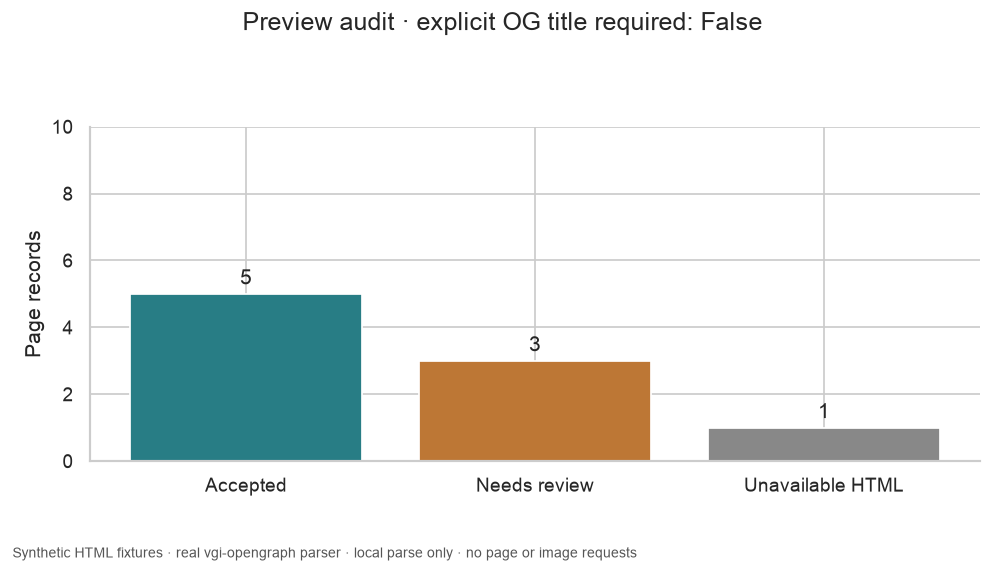

In [11]:
display(audit_table)
assert len(audit_table) == len(parsed_table)
assert (
    con.execute(
        "SELECT count(*) FROM audit WHERE outcome='Accepted' AND (NOT base_pass OR NOT html_available)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM audit WHERE outcome='Accepted' AND ? AND NOT has_og_title", [REQUIRE_OG_TITLE]
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM audit WHERE (outcome='Unavailable HTML') IS DISTINCT FROM (NOT html_available)"
    ).fetchone()[0]
    == 0
)
outcomes = con.execute(
    "SELECT labels.outcome,count(a.page_id) AS pages FROM (VALUES ('Accepted'),('Needs review'),('Unavailable HTML')) labels(outcome) LEFT JOIN audit a USING(outcome) GROUP BY labels.outcome ORDER BY labels.outcome"
).df()
assert outcomes.pages.sum() == len(audit_table)
accepted = con.execute("SELECT count(*) FROM audit WHERE outcome='Accepted'").fetchone()[0]
base_count = con.execute("SELECT count(*) FROM audit WHERE base_pass").fetchone()[0]
prose(
    f"With `REQUIRE_OG_TITLE={REQUIRE_OG_TITLE}`, **{accepted}/{len(audit_table)} corpus records** are accepted. The fallback-friendly base rule admits **{base_count}**, so the explicit-title requirement excludes **{base_count - accepted} additional pages** in this run. **{int((audit_table.outcome == 'Unavailable HTML').sum())}** input remains unavailable. These are policy outcomes for synthetic examples, not site quality scores."
)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(outcomes.outcome, outcomes.pages, color=[colors[x] for x in outcomes.outcome])
ax.bar_label(bars, fmt="%d", padding=3)
ax.set(ylabel="Page records", ylim=(0, len(audit_table) + 1))
ax.yaxis.get_major_locator().set_params(integer=True)
fig.suptitle(f"Preview audit · explicit OG title required: {REQUIRE_OG_TITLE}")
finish(fig)

## Experiment: require an explicit OG title

Change only `REQUIRE_OG_TITLE` from **False to True**. Predict that acceptance cannot increase. Compare the accepted page IDs and the outcome chart: the Twitter and HTML title fallbacks still parse correctly but no longer satisfy this stricter policy.

The input hash, parsed fingerprint, availability matrix, conflicting-title rows and ordered-image table must remain identical. The conflicting-title page stays flagged under both rules. Restore **False** afterwards. Requiring one explicit property does not turn this limited audit into a full Open Graph validator.

In [12]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)